# Active reset diagnostic

Checks whether `ConditionalReset`'s corrective X is actually firing, or whether an active-reset run only looks correct after adding a long idle buffer because that buffer is really just giving the qubit time to relax via T1 (not because of readout-resonator photon decay, which is normally ~1us, not tens of us).

Four branches per repetition, all freshly thermal-reset beforehand:
- `raw_0`: `Reset -> Measure` (ground reference)
- `raw_1`: `Reset -> X -> Measure` (|1>, no active reset at all)
- `reset_immediate`: `Reset -> X -> ConditionalReset -> Measure` (buffer = 0)
- `reset_buffered`: `Reset -> X -> ConditionalReset -> IdlePulse(buffer) -> Measure`

If the conditional X is firing, `reset_immediate` should already sit closer to `raw_0` than to `raw_1`. If `reset_immediate` looks like `raw_1`, the conditional correction isn't happening, and any recovery in `reset_buffered` is just T1 decay during the buffer.

In [1]:
from pathlib import Path

from qblox_lab.config.sessions import CONFIG_DIR, SESSIONS
from qblox_lab.config.session_paths import save_config_snapshot
from qblox_lab.experiments.dev_active_reset_diagnostic import ActiveResetDiagnostic


## Run parameters

In [2]:
SESSION = SESSIONS["AS_QRC"]
HARDWARE_CONFIG = SESSION.hardware_config
DEVICE_CONFIG = SESSION.device_config
FLUX_CONFIG = SESSION.flux_config  # If None, leave the existing hardware flux unchanged
OUTPUT_DIR = SESSION.output_dir
EXPERIMENT_NAME = "active_reset_diagnostic"

QUBIT = "q1"
REPETITIONS = 2000
BUFFER = 1e-6  # s, idle buffer for the reset_buffered branch. Sweep this
               # (e.g. 0, 1e-6, 5e-6, 1e-5, 5e-5) and rerun to see how
               # reset_buffered's recovery scales with buffer duration --
               # compare the timescale to this qubit's independently
               # measured T1.

TIMEOUT = 300
CREATE_DUMMY_CONNECTIONS = False

PLOT_RESULTS = True


## Hardware and experiment

In [3]:
import atexit

from qcodes.instrument import Instrument

from qblox_lab.config.hardware import create_hardware_agent

hardware_agent = create_hardware_agent(
    hardware_configuration=HARDWARE_CONFIG,
    device_configuration=DEVICE_CONFIG,
    output_dir=OUTPUT_DIR,
    create_dummy_connections=CREATE_DUMMY_CONNECTIONS,
)

experiment = ActiveResetDiagnostic(
    hardware_agent=hardware_agent,
    qubit_name=QUBIT,
    flux_config=FLUX_CONFIG,
)

atexit.register(Instrument.close_all)


<bound method Instrument.close_all of <class 'qcodes.instrument.instrument.Instrument'>>

## Measurement

In [4]:
dataset = experiment.run_measurement(
    repetitions=REPETITIONS,
    buffer=BUFFER,
    timeout=TIMEOUT,
)
dataset


/home/reny871224/qblox-measurement-nodes/.venv/lib/python3.11/site-packages/qblox_scheduler/operations/gate_library.py:1181: FutureWarning: Using the `acq_channel` argument is deprecated. Use the `acq_label` argument instead.
  warn_acq_channel()


---
---
---
---


<xarray.Dataset> Size: 448kB
Dimensions:            (acq_index_diag_q1: 8000, acq_index_cond_q1: 4000)
Coordinates:
  * acq_index_diag_q1  (acq_index_diag_q1) int64 64kB 0 1 2 3 ... 7997 7998 7999
    rep_q1             (acq_index_diag_q1) int64 64kB 0 0 0 0 ... 1999 1999 1999
    branch_q1          (acq_index_diag_q1) int64 64kB 0 1 2 3 0 1 ... 3 0 1 2 3
  * acq_index_cond_q1  (acq_index_cond_q1) int64 32kB 0 1 2 3 ... 3997 3998 3999
    cond_branch_q1     (acq_index_cond_q1) int64 32kB 2 3 2 3 2 3 ... 3 2 3 2 3
    cond_rep_q1        (acq_index_cond_q1) int64 32kB 0 0 1 1 ... 1998 1999 1999
Data variables:
    diag_q1            (acq_index_diag_q1) complex128 128kB (-0.0003909223079...
    cond_q1            (acq_index_cond_q1) float64 32kB 1.0 1.0 0.0 ... 0.0 1.0
Attributes:
    tuid:     20260917-062155-835-e7dbb5

## Analysis

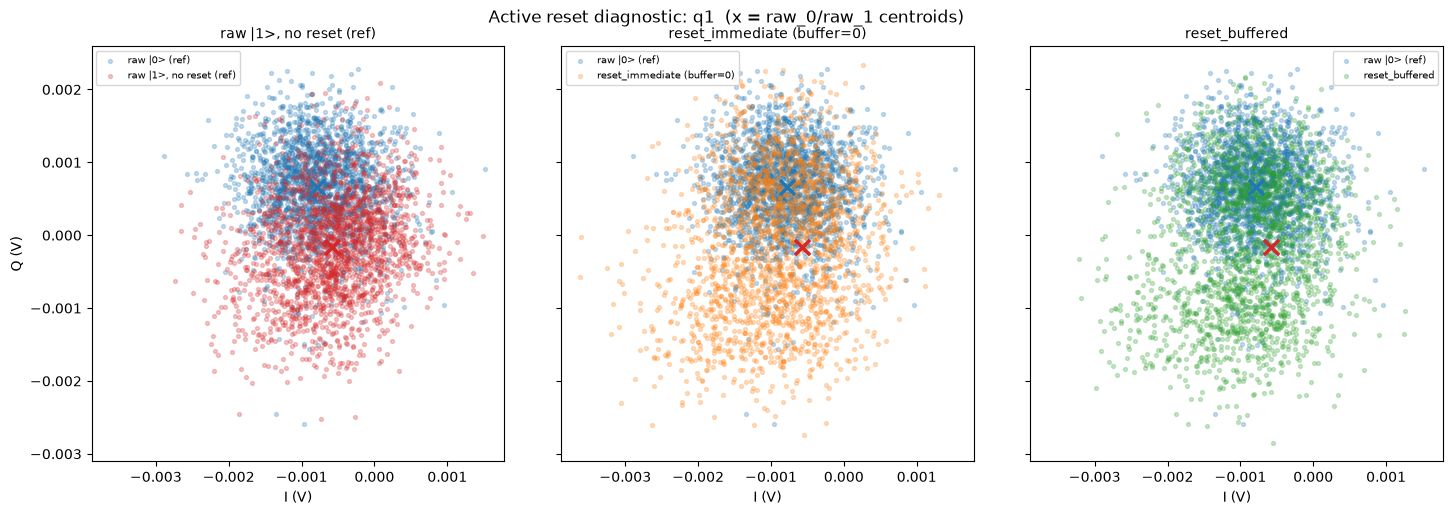

Fraction classified near |0> (raw_0/raw_1 midpoint split):
  raw_0 (sanity, expect ~100%):    78.1%
  raw_1 (sanity, expect ~0%):      26.6%
  reset_immediate (buffer=0):      39.9%
  reset_buffered:                  39.4%
If raw_0/raw_1 aren't close to their expected ~100%/~0%, this qubit's own single-shot readout fidelity is too low for this test to be conclusive on its own -- check cal13_iq_blob's thermal-reset fidelity first. Otherwise: if reset_immediate is close to raw_1's fraction, the conditional X is not firing; recovery in reset_buffered would then be T1 decay during the buffer, not active reset.

ConditionalReset's own real-time decision, split by branch:
  reset_immediate:
    hardware detected |1> (should fire corrective X): 73.3%  (compare to this qubit's own |1> readout fidelity, e.g. cal13's fid_est_1)
    of those, ended up near |0> afterward: 39.0%  -- low here despite a normal detection rate above means the corrective X isn't landing (feedback-trigger path), not a di

In [5]:
result = experiment.analysis()
if PLOT_RESULTS:
    experiment.plot(result)


## Save

In [ ]:
save_config_snapshot(SESSION, dataset, EXPERIMENT_NAME)


## Release hardware connection

In [ ]:
from qcodes.instrument import Instrument

Instrument.close_all()
